Goal : Getting the differential peaks of H3K4me1 with  spikein for all D2 comparaison

In [ ]:
library(data.table)
library(DiffBind)
library(TxDb.Mmusculus.UCSC.mm10.knownGene)
library(org.Mm.eg.db)
library(dplyr)

In [ ]:
bam_files <- list.files(
  path = "/data/bams",
  pattern = "*_CnT_H3K4me1.*\\.bam$",
  full.names = TRUE
)

bam_files

[1] "/data/bams/E14_2iD0_TKO_H3_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_089_trimV5_mm10.bam"  
 [2] "/data/bams/E14_2iD0_TKO_H3_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_093_trimV5_mm10.bam"  
 [3] "/data/bams/E14_2iD0_TKO_K4M_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_090_trimV5_mm10.bam" 
 [4] "/data/bams/E14_2iD0_TKO_K4M_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_094_trimV5_mm10.bam" 
 [5] "/data/bams/E14_2iD0_WT_H3_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_087_trimV5_mm10.bam"   
 [6] "/data/bams/E14_2iD0_WT_H3_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_091_trimV5_mm10.bam"   
 [7] "/data/bams/E14_2iD0_WT_K4M_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_088_trimV5_mm10.bam"  
 [8] "/data/bams/E14_2iD0_WT_K4M_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_092_trimV5_mm10.bam"  
 [9] "/data/bams/E14_EpiD2_TKO_H3_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_097_trimV5_mm10.bam" 
[10] "/data/bams/E14_EpiD2_TKO_H3_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_101_trimV5_mm10.bam" 
[11] "/data/bams/E14_EpiD2_TKO_K4M_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_098_trimV5_mm10.bam"
[12] "/data/bams/E14_EpiD2_TKO_K4M_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_102_trimV5_mm10.bam"
[13] "/data/bams/E14_EpiD2_WT_H3_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_095_trimV5_mm10.bam"  
[14] "/data/bams/E14_EpiD2_WT_H3_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_099_trimV5_mm10.bam"  
[15] "/data/bams/E14_EpiD2_WT_K4M_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_096_trimV5_mm10.bam" 
[16] "/data/bams/E14_EpiD2_WT_K4M_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_100_trimV5_mm10.bam"

In [2]:
peak_files <- list.files(
  path = "/scratch/Narjesse/scripts/H3K4me1/peakcalling/results",
    pattern = "*_CnT_H3K4me1.*\\.broadPeak$",
  full.names = TRUE
)
peak_files

[1] "/scratch/Narjesse/scripts/H3K4me1/peakcalling/results/E14_2iD0_TKO_H3_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_089_trimV5_mm10.filtered.broadPeak"  
 [2] "/scratch/Narjesse/scripts/H3K4me1/peakcalling/results/E14_2iD0_TKO_H3_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_093_trimV5_mm10.filtered.broadPeak"  
 [3] "/scratch/Narjesse/scripts/H3K4me1/peakcalling/results/E14_2iD0_TKO_K4M_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_090_trimV5_mm10.filtered.broadPeak" 
 [4] "/scratch/Narjesse/scripts/H3K4me1/peakcalling/results/E14_2iD0_TKO_K4M_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_094_trimV5_mm10.filtered.broadPeak" 
 [5] "/scratch/Narjesse/scripts/H3K4me1/peakcalling/results/E14_2iD0_WT_H3_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_087_trimV5_mm10.filtered.broadPeak"   
 [6] "/scratch/Narjesse/scripts/H3K4me1/peakcalling/results/E14_2iD0_WT_H3_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_091_trimV5_mm10.filtered.broadPeak"   
 [7] "/scratch/Narjesse/scripts/H3K4me1/peakcalling/results/E14_2iD0_WT_K4M_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_088_trimV5_mm10.filtered.broadPeak"  
 [8] "/scratch/Narjesse/scripts/H3K4me1/peakcalling/results/E14_2iD0_WT_K4M_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_092_trimV5_mm10.filtered.broadPeak"  
 [9] "/scratch/Narjesse/scripts/H3K4me1/peakcalling/results/E14_EpiD2_TKO_H3_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_097_trimV5_mm10.filtered.broadPeak" 
[10] "/scratch/Narjesse/scripts/H3K4me1/peakcalling/results/E14_EpiD2_TKO_H3_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_101_trimV5_mm10.filtered.broadPeak" 
[11] "/scratch/Narjesse/scripts/H3K4me1/peakcalling/results/E14_EpiD2_TKO_K4M_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_098_trimV5_mm10.filtered.broadPeak"
[12] "/scratch/Narjesse/scripts/H3K4me1/peakcalling/results/E14_EpiD2_TKO_K4M_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_102_trimV5_mm10.filtered.broadPeak"
[13] "/scratch/Narjesse/scripts/H3K4me1/peakcalling/results/E14_EpiD2_WT_H3_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_095_trimV5_mm10.filtered.broadPeak"  
[14] "/scratch/Narjesse/scripts/H3K4me1/peakcalling/results/E14_EpiD2_WT_H3_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_099_trimV5_mm10.filtered.broadPeak"  
[15] "/scratch/Narjesse/scripts/H3K4me1/peakcalling/results/E14_EpiD2_WT_K4M_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_096_trimV5_mm10.filtered.broadPeak" 
[16] "/scratch/Narjesse/scripts/H3K4me1/peakcalling/results/E14_EpiD2_WT_K4M_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_100_trimV5_mm10.filtered.broadPeak"

In [ ]:
#list of bam file containing the spike in
spike_files <- c( "/scratch/Narjesse/scripts/H3K4me1/alignement/AD_089_MKDL250006889-1A_22VVL2LT4_L8_NH/AD_089_MKDL250006889-1A_22VVL2LT4_L8_NH_raw_sorted.bam",
                 "/scratch/Narjesse/scripts/H3K4me1/alignement/AD_093_MKDL250006893-1A_22VVL2LT4_L8_NH/AD_093_MKDL250006893-1A_22VVL2LT4_L8_NH_raw_sorted.bam",
                 "/scratch/Narjesse/scripts/H3K4me1/alignement/AD_090_MKDL250006890-1A_22VVL2LT4_L8_NH/AD_090_MKDL250006890-1A_22VVL2LT4_L8_NH_raw_sorted.bam",
                 "/scratch/Narjesse/scripts/H3K4me1/alignement/AD_094_MKDL250006894-1A_22VVL2LT4_L8_NH/AD_094_MKDL250006894-1A_22VVL2LT4_L8_NH_raw_sorted.bam",
                 "/scratch/Narjesse/scripts/H3K4me1/alignement/AD_087_MKDL250006887-1A_22VVL2LT4_L8_NH/AD_087_MKDL250006887-1A_22VVL2LT4_L8_NH_raw_sorted.bam",
                 "/scratch/Narjesse/scripts/H3K4me1/alignement/AD_091_MKDL250006891-1A_22VVL2LT4_L8_NH/AD_091_MKDL250006891-1A_22VVL2LT4_L8_NH_raw_sorted.bam",
                 "/scratch/Narjesse/scripts/H3K4me1/alignement/AD_088_MKDL250006888-1A_22VVL2LT4_L8_NH/AD_088_MKDL250006888-1A_22VVL2LT4_L8_NH_raw_sorted.bam",
                 "/scratch/Narjesse/scripts/H3K4me1/alignement/AD_092_MKDL250006892-1A_22VVL2LT4_L8_NH/AD_092_MKDL250006892-1A_22VVL2LT4_L8_NH_raw_sorted.bam",
                 "/scratch/Narjesse/scripts/H3K4me1/alignement/AD_097_MKDL250006897-1A_22VVL2LT4_L8_NH/AD_097_MKDL250006897-1A_22VVL2LT4_L8_NH_raw_sorted.bam",
                 "/scratch/Narjesse/scripts/H3K4me1/alignement/AD_101_MKDL250006901-1A_22VVL2LT4_L8_NH/AD_101_MKDL250006901-1A_22VVL2LT4_L8_NH_raw_sorted.bam",
                 "/scratch/Narjesse/scripts/H3K4me1/alignement/AD_098_MKDL250006898-1A_22VVL2LT4_L8_NH/AD_098_MKDL250006898-1A_22VVL2LT4_L8_NH_raw_sorted.bam",
                 "/scratch/Narjesse/scripts/H3K4me1/alignement/AD_102_MKDL250006902-1A_22VVL2LT4_L8_NH/AD_102_MKDL250006902-1A_22VVL2LT4_L8_NH_raw_sorted.bam",
                 "/scratch/Narjesse/scripts/H3K4me1/alignement/AD_095_MKDL250006895-1A_22VVL2LT4_L8_NH/AD_095_MKDL250006895-1A_22VVL2LT4_L8_NH_raw_sorted.bam",
                 "/scratch/Narjesse/scripts/H3K4me1/alignement/AD_099_MKDL250006899-1A_22VVL2LT4_L8_NH/AD_099_MKDL250006899-1A_22VVL2LT4_L8_NH_raw_sorted.bam",
                 "/scratch/Narjesse/scripts/H3K4me1/alignement/AD_096_MKDL250006896-1A_22VVL2LT4_L8_NH/AD_096_MKDL250006896-1A_22VVL2LT4_L8_NH_raw_sorted.bam",
                 "/scratch/Narjesse/scripts/H3K4me1/alignement/AD_100_MKDL250006900-1A_22VVL2LT4_L8_NH/AD_100_MKDL250006900-1A_22VVL2LT4_L8_NH_raw_sorted.bam"

    
)

In [ ]:
#creating the sample sheet
sample_names <- c("D0_TKO_H3_1","D0_TKO_H3_2","D0_TKO_K4M_1","D0_TKO_K4M_2","D0_WT_H3_1", "D0_WT_H3_2","D0_WT_K4M_1","D0_WT_K4M_2","D2_TKO_H3_1","D2_TKO_H3_2","D2_TKO_K4M_1", "D2_TKO_K4M_2","D2_WT_H3_1", "D2_WT_H3_2","D2_WT_K4M_1","D2_WT_K4M_2")

treatment <- c("D0_TKO_H3","D0_TKO_H3","D0_TKO_K4M","D0_TKO_K4M","D0_WT_H3", "D0_WT_H3","D0_WT_K4M","D0_WT_K4M","D2_TKO_H3","D2_TKO_H3","D2_TKO_K4M","D2_TKO_K4M","D2_WT_H3", "D2_WT_H3","D2_WT_K4M","D2_WT_K4M")

sample_sheet <- data.frame(
  SampleID = sample_names,       
  Condition = treatment,         
  bamReads = bam_files,          
  Peaks = peak_files,            
  PeakCaller = "broad",
  Spikein = spike_files,
  stringsAsFactors = FALSE
)
 write.csv(sample_sheet, "H3K4me1_spikein_seq_sample_sheet.csv", row.names = FALSE)

In [8]:
head(sample_sheet)

,SampleID,Condition,bamReads,Peaks,PeakCaller,Spikein
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,D0_TKO_H3_1,D0_TKO_H3,/data/bams/E14_2iD0_TKO_H3_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_089_trimV5_mm10.bam,/scratch/Narjesse/scripts/H3K4me1/peakcalling/results/E14_2iD0_TKO_H3_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_089_trimV5_mm10.filtered.broadPeak,broad,/scratch/Narjesse/scripts/H3K4me1/alignement/AD_089_MKDL250006889-1A_22VVL2LT4_L8_NH/AD_089_MKDL250006889-1A_22VVL2LT4_L8_NH_raw_sorted.bam
2,D0_TKO_H3_2,D0_TKO_H3,/data/bams/E14_2iD0_TKO_H3_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_093_trimV5_mm10.bam,/scratch/Narjesse/scripts/H3K4me1/peakcalling/results/E14_2iD0_TKO_H3_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_093_trimV5_mm10.filtered.broadPeak,broad,/scratch/Narjesse/scripts/H3K4me1/alignement/AD_093_MKDL250006893-1A_22VVL2LT4_L8_NH/AD_093_MKDL250006893-1A_22VVL2LT4_L8_NH_raw_sorted.bam
3,D0_TKO_K4M_1,D0_TKO_K4M,/data/bams/E14_2iD0_TKO_K4M_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_090_trimV5_mm10.bam,/scratch/Narjesse/scripts/H3K4me1/peakcalling/results/E14_2iD0_TKO_K4M_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_090_trimV5_mm10.filtered.broadPeak,broad,/scratch/Narjesse/scripts/H3K4me1/alignement/AD_090_MKDL250006890-1A_22VVL2LT4_L8_NH/AD_090_MKDL250006890-1A_22VVL2LT4_L8_NH_raw_sorted.bam
4,D0_TKO_K4M_2,D0_TKO_K4M,/data/bams/E14_2iD0_TKO_K4M_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_094_trimV5_mm10.bam,/scratch/Narjesse/scripts/H3K4me1/peakcalling/results/E14_2iD0_TKO_K4M_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_094_trimV5_mm10.filtered.broadPeak,broad,/scratch/Narjesse/scripts/H3K4me1/alignement/AD_094_MKDL250006894-1A_22VVL2LT4_L8_NH/AD_094_MKDL250006894-1A_22VVL2LT4_L8_NH_raw_sorted.bam
5,D0_WT_H3_1,D0_WT_H3,/data/bams/E14_2iD0_WT_H3_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_087_trimV5_mm10.bam,/scratch/Narjesse/scripts/H3K4me1/peakcalling/results/E14_2iD0_WT_H3_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_087_trimV5_mm10.filtered.broadPeak,broad,/scratch/Narjesse/scripts/H3K4me1/alignement/AD_087_MKDL250006887-1A_22VVL2LT4_L8_NH/AD_087_MKDL250006887-1A_22VVL2LT4_L8_NH_raw_sorted.bam
6,D0_WT_H3_2,D0_WT_H3,/data/bams/E14_2iD0_WT_H3_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_091_trimV5_mm10.bam,/scratch/Narjesse/scripts/H3K4me1/peakcalling/results/E14_2iD0_WT_H3_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_091_trimV5_mm10.filtered.broadPeak,broad,/scratch/Narjesse/scripts/H3K4me1/alignement/AD_091_MKDL250006891-1A_22VVL2LT4_L8_NH/AD_091_MKDL250006891-1A_22VVL2LT4_L8_NH_raw_sorted.bam


In [7]:
atac_db <- dba(sampleSheet = sample_sheet, scoreCol=5)
dba.show(atac_db)

D0_TKO_H3_1   D0_TKO_H3  NA broad

D0_TKO_H3_2   D0_TKO_H3  NA broad

D0_TKO_K4M_1   D0_TKO_K4M  NA broad

D0_TKO_K4M_2   D0_TKO_K4M  NA broad

D0_WT_H3_1   D0_WT_H3  NA broad

D0_WT_H3_2   D0_WT_H3  NA broad

D0_WT_K4M_1   D0_WT_K4M  NA broad

D0_WT_K4M_2   D0_WT_K4M  NA broad

D2_TKO_H3_1   D2_TKO_H3  NA broad

D2_TKO_H3_2   D2_TKO_H3  NA broad

D2_TKO_K4M_1   D2_TKO_K4M  NA broad

D2_TKO_K4M_2   D2_TKO_K4M  NA broad

D2_WT_H3_1   D2_WT_H3  NA broad

D2_WT_H3_2   D2_WT_H3  NA broad

D2_WT_K4M_1   D2_WT_K4M  NA broad

D2_WT_K4M_2   D2_WT_K4M  NA broad



,ID,Condition,Caller,Intervals
,<chr>,<chr>,<chr>,<dbl>
1,D0_TKO_H3_1,D0_TKO_H3,broad,71206
2,D0_TKO_H3_2,D0_TKO_H3,broad,79021
3,D0_TKO_K4M_1,D0_TKO_K4M,broad,55959
4,D0_TKO_K4M_2,D0_TKO_K4M,broad,50063
5,D0_WT_H3_1,D0_WT_H3,broad,80182
6,D0_WT_H3_2,D0_WT_H3,broad,76708
7,D0_WT_K4M_1,D0_WT_K4M,broad,59018
8,D0_WT_K4M_2,D0_WT_K4M,broad,51152
9,D2_TKO_H3_1,D2_TKO_H3,broad,83747


In [ ]:
# creating and saving the count matrix
atac_db<-dba.count(atac_db, summits = FALSE, bParallel=FALSE)
save(atac_db, file = "H3K4me1_spikein_db_full_counts.RData")

Sample: /data/bams/E14_2iD0_TKO_H3_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_089_trimV5_mm10.bam125 

Reads will be counted as Paired-end.

Sample: /data/bams/E14_2iD0_TKO_H3_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_093_trimV5_mm10.bam125 

Reads will be counted as Paired-end.

Sample: /data/bams/E14_2iD0_TKO_K4M_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_090_trimV5_mm10.bam125 

Reads will be counted as Paired-end.

Sample: /data/bams/E14_2iD0_TKO_K4M_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_094_trimV5_mm10.bam125 

Reads will be counted as Paired-end.

Sample: /data/bams/E14_2iD0_WT_H3_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_087_trimV5_mm10.bam125 

Reads will be counted as Paired-end.

Sample: /data/bams/E14_2iD0_WT_H3_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD_091_trimV5_mm10.bam125 

Reads will be counted as Paired-end.

Sample: /data/bams/E14_2iD0_WT_K4M_doxPos_rep1_CnT_H3K4me1_SpikeIn_AD_088_trimV5_mm10.bam125 

Reads will be counted as Paired-end.

Sample: /data/bams/E14_2iD0_WT_K4M_doxPos_rep2_CnT_H3K4me1_SpikeIn_AD

In [2]:
load("H3K4me1_spikein_db_full_counts.RData")

In [3]:
dba.show(atac_db)
counts <- dba.peakset(atac_db, bRetrieve = TRUE)
head(counts)

,ID,Condition,Caller,Intervals,Reads,FRiP
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
1,D0_TKO_H3_1,D0_TKO_H3,counts,109563,15537130,0.78
2,D0_TKO_H3_2,D0_TKO_H3,counts,109563,22703452,0.72
3,D0_TKO_K4M_1,D0_TKO_K4M,counts,109563,11583706,0.79
4,D0_TKO_K4M_2,D0_TKO_K4M,counts,109563,17744094,0.77
5,D0_WT_H3_1,D0_WT_H3,counts,109563,20111614,0.77
6,D0_WT_H3_2,D0_WT_H3,counts,109563,18141770,0.77
7,D0_WT_K4M_1,D0_WT_K4M,counts,109563,14879448,0.80
8,D0_WT_K4M_2,D0_WT_K4M,counts,109563,14372472,0.79
9,D2_TKO_H3_1,D2_TKO_H3,counts,109563,19238301,0.66


GRanges object with 6 ranges and 16 metadata columns:
    seqnames          ranges strand | D0_TKO_H3_1 D0_TKO_H3_2 D0_TKO_K4M_1
       <Rle>       <IRanges>  <Rle> |   <numeric>   <numeric>    <numeric>
  1     chr1 3190796-3192154      * |     3.86202    0.000000      1.29502
  2     chr1 3263774-3264557      * |     0.00000    0.000000      2.59005
  3     chr1 3327898-3328627      * |     1.93101    0.660744      0.00000
  4     chr1 3343180-3344421      * |    32.82717   10.571908     18.13033
  5     chr1 3361041-3361794      * |     7.72404    4.625210      3.88507
  6     chr1 3377196-3377837      * |     0.00000    1.321488      0.00000
    D0_TKO_K4M_2 D0_WT_H3_1 D0_WT_H3_2 D0_WT_K4M_1 D0_WT_K4M_2 D2_TKO_H3_1
       <numeric>  <numeric>  <numeric>   <numeric>   <numeric>   <numeric>
  1     2.536254   4.475377   2.480658     1.00818     3.13123     31.1902
  2     0.845418   0.745896   0.000000     0.00000     0.00000     24.9522
  3     1.690836   0.745896   0.826886     0.0

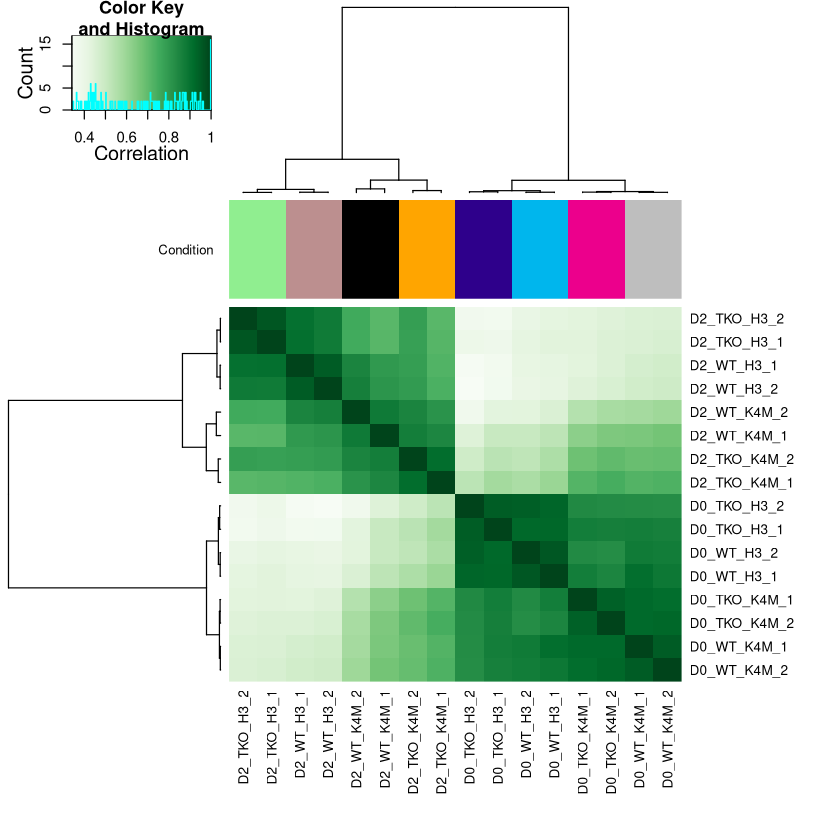

In [10]:
dba.plotHeatmap(atac_db)

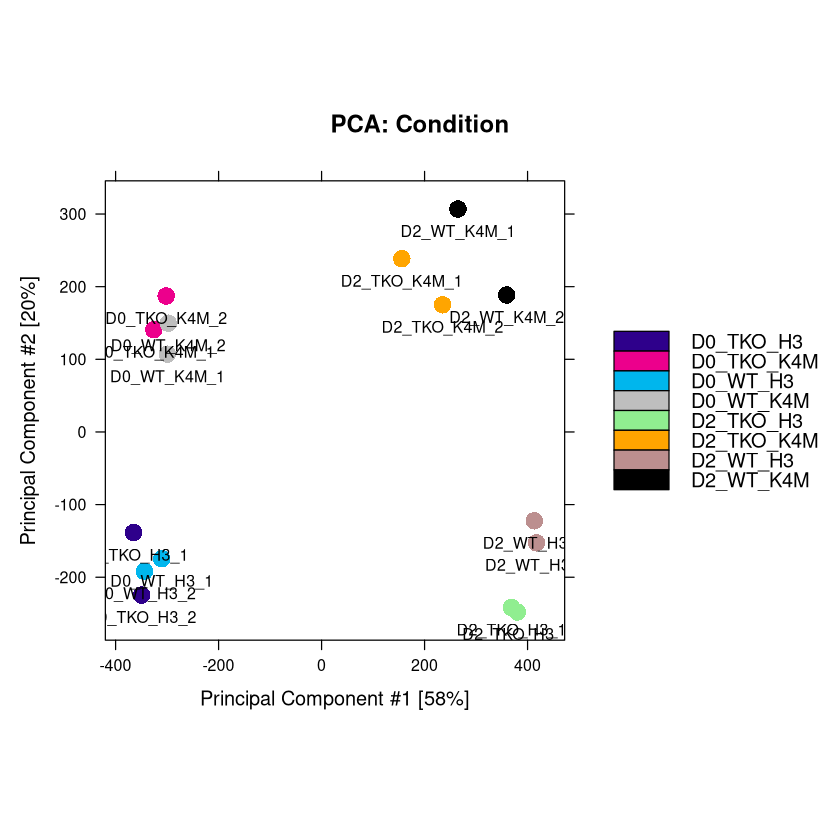

In [11]:
dba.plotPCA(atac_db, DBA_CONDITION, label=DBA_ID)


# WT D0 H3 vs WT D0 K4M 

In [ ]:
# define contrast
D0_db_H3_WT_vs_K4M_WT <- dba.contrast(
  atac_db,
  contrast = c("Condition", "D0_WT_K4M", "D0_WT_H3"),
  minMembers = 2
)
D0_db_H3_WT_vs_K4M_WT <- dba.normalize(D0_db_H3_WT_vs_K4M_WT, spikein = TRUE)
D0_db_H3_WT_vs_K4M_WT <- dba.analyze(D0_db_H3_WT_vs_K4M_WT)
dba.show(D0_db_H3_WT_vs_K4M_WT, bContrasts = TRUE)

Computing results names...

Generating counts for spike-ins...

Applying Blacklist/Greylists...

Genome detected: Mmusculus.UCSC.mm10

Applying blacklist...

Removed: 1510 of 109563 intervals.

Re-normalizing...

Removed 1510 (of 109563) consensus peaks.

Analyzing...

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



,Factor,Group,Samples,Group2,Samples2,DB.DESeq2
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Condition,D0_WT_K4M,2,D0_WT_H3,2,73946


In [ ]:
#get only the differential peak
diff_peaks_D0_H3_WT_vs_K4M_WT <- dba.report(D0_db_H3_WT_vs_K4M_WT, th = 0.05)
length(diff_peaks_D0_H3_WT_vs_K4M_WT)
head(diff_peaks_D0_H3_WT_vs_K4M_WT)
diff_peaks_D0_H3_WT_vs_K4M_WT <- as.data.frame(diff_peaks_D0_H3_WT_vs_K4M_WT)

[1] 73946

GRanges object with 6 ranges and 6 metadata columns:
        seqnames              ranges strand |      Conc Conc_D0_WT_K4M
           <Rle>           <IRanges>  <Rle> | <numeric>      <numeric>
  87935     chr7   17999260-18002185      * |   7.34795        4.14786
   1149     chr1   39291568-39295412      * |   7.80599        5.15115
   8994    chr10   42649032-42652910      * |   6.64745        3.82015
   1910     chr1   60816941-60820032      * |   7.42546        4.54299
  93597     chr7 139971477-139974339      * |   7.52493        5.24652
  59495     chr2 145769906-145773223      * |   7.78291        5.11622
        Conc_D0_WT_H3      Fold     p-value         FDR
            <numeric> <numeric>   <numeric>   <numeric>
  87935       8.26725  -3.91186 6.63896e-22 7.17360e-17
   1149       8.68665  -3.38047 3.57797e-19 1.93305e-14
   8994       7.54205  -3.53347 7.59757e-18 2.14137e-13
   1910       8.32417  -3.57957 7.92710e-18 2.14137e-13
  93597       8.36801  -3.00410 1.92747e-17

In [12]:
summary(diff_peaks_D0_H3_WT_vs_K4M_WT$Fold)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 -4.336  -2.496  -2.109  -2.103  -1.711   2.039 

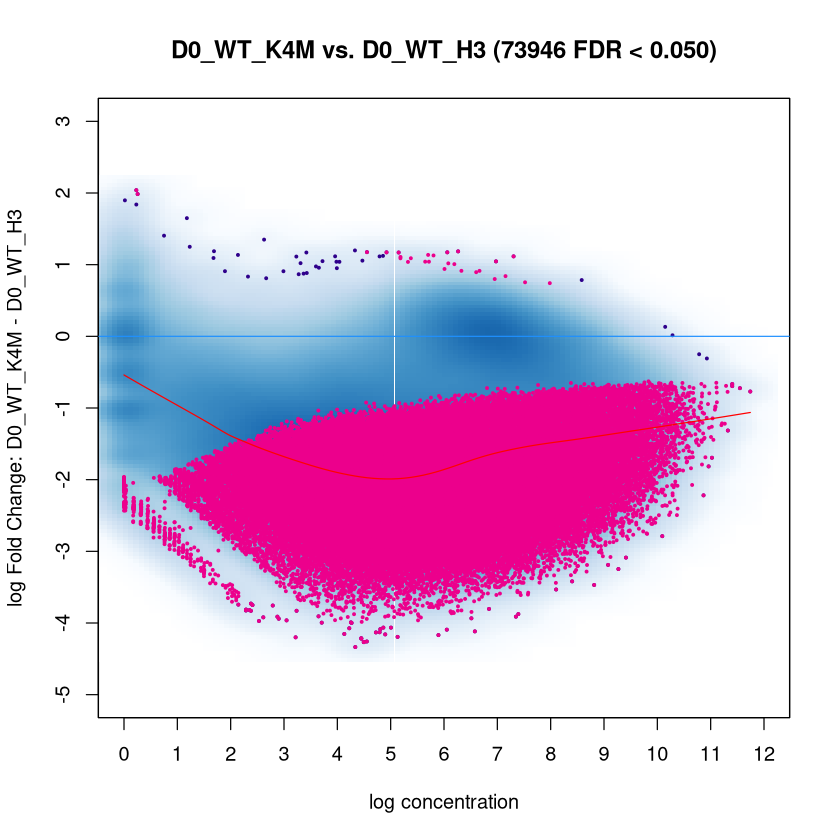

In [6]:
dba.plotMA(D0_db_H3_WT_vs_K4M_WT)

In [13]:
pdf("Volcanoplot_diffbind_H3K4me1/D0_H3_WT_vs_K4M_WT.pdf", width = 8, height = 6)
dba.plotVolcano(D0_db_H3_WT_vs_K4M_WT, contrast=1) 
dev.off()

png 
  2

In [ ]:
#get the list of up and down peaks
setwd("/scratch/Narjesse/scripts/H3K4me1/Diffbind_Spikein/bed")
D0_WT_H3_enrich <- diff_peaks_D0_H3_WT_vs_K4M_WT %>% 
  dplyr::filter(FDR < 0.05 & Fold < 0) %>% 
  dplyr::select(seqnames, start, end)
# Write to file
write.table(D0_WT_H3_enrich, file="D0_WT_H3_enriched_D0_H3_WT_vs_D0_K4M_WT.bed", sep="\t", quote=F, row.names=F, col.names=F)

D0_WT_K4M_enrich <- diff_peaks_D0_H3_WT_vs_K4M_WT %>% 
  dplyr::filter(FDR < 0.05 & Fold > 0) %>% 
  dplyr::select(seqnames, start, end)

# Write to file
write.table(D0_WT_K4M_enrich, file="D0_WT_K4M_enriched_D0_H3_WT_vs_D0_K4M_WT.bed", sep="\t", quote=F, row.names=F, col.names=F)

In [9]:
cat("number of DO WT H3 enriched peaks :", nrow(D0_WT_H3_enrich),"\n")

number of DO WT H3 enriched peaks : 73919 


In [10]:
cat("number of D0_WT_K4M_enrich peaks :", nrow(D0_WT_K4M_enrich))

number of D0_WT_K4M_enrich peaks : 27

# WT D2 H3 vs WT D2 K4M 


In [14]:
D2_db_H3_WT_vs_K4M_WT <- dba.contrast(
  atac_db,
  contrast = c("Condition", "D2_WT_K4M", "D2_WT_H3"),
  minMembers = 2
)
D2_db_H3_WT_vs_K4M_WT <- dba.normalize(D2_db_H3_WT_vs_K4M_WT, spikein = TRUE)
D2_db_H3_WT_vs_K4M_WT <- dba.analyze(D2_db_H3_WT_vs_K4M_WT)
dba.show(D2_db_H3_WT_vs_K4M_WT, bContrasts = TRUE)

Computing results names...

Generating counts for spike-ins...

Applying Blacklist/Greylists...

Genome detected: Mmusculus.UCSC.mm10

Applying blacklist...

Removed: 1510 of 109563 intervals.

Re-normalizing...

Removed 1510 (of 109563) consensus peaks.

Analyzing...

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



,Factor,Group,Samples,Group2,Samples2,DB.DESeq2
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Condition,D2_WT_K4M,2,D2_WT_H3,2,88741


In [15]:
df <- dba.report(D2_db_H3_WT_vs_K4M_WT,th = 1, DataType = DBA_DATA_FRAME)
write.table(df, file="Comparaison_diffbind_spikein_H3K4me1/D2_WT_K4M_vs_D2_WT_H3_H3K4me1.bed", sep="\t", quote=F, row.names=F, col.names=TRUE)


Warning message in file(file, ifelse(append, "a", "w")):
“cannot open file 'Comparaison_diffbind_spikein_H3K4me1/D2_WT_K4M_vs_D2_WT_H3_H3K4me1.bed': No such file or directory”


ERROR: Error in file(file, ifelse(append, "a", "w")): cannot open the connection


In [16]:
head(df)
nrow(df)

,Chr,Start,End,Conc,Conc_D2_WT_K4M,Conc_D2_WT_H3,Fold,p-value,FDR
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
9176,chr10,45070630,45076751,7.694434,4.382513,8.619904,-4.132655,1.865215e-25,1.771567e-20
48317,chr18,42051600,42055707,8.736475,5.131109,9.675955,-4.427265,3.279070e-25,1.771567e-20
305,chr1,12805697,12812190,8.873605,6.351005,9.742269,-3.333540,2.099505e-24,7.561928e-20
56291,chr2,69045966,69051355,8.962905,5.896559,9.874112,-3.884682,1.036255e-22,2.799262e-18
79817,chr5,129965683,129969994,8.090649,5.119744,8.995578,-3.787750,3.311736e-22,6.106895e-18
35657,chr15,55138968,55149238,8.808371,5.761921,9.718306,-3.864678,3.391055e-22,6.106895e-18


[1] 108053

In [17]:
diff_peaks_D2_H3_WT_vs_K4M_WT <- dba.report(D2_db_H3_WT_vs_K4M_WT, th = 0.05)
length(diff_peaks_D2_H3_WT_vs_K4M_WT)
head(diff_peaks_D2_H3_WT_vs_K4M_WT)
diff_peaks_D2_H3_WT_vs_K4M_WT <- as.data.frame(diff_peaks_D2_H3_WT_vs_K4M_WT)

[1] 88741

GRanges object with 6 ranges and 6 metadata columns:
        seqnames              ranges strand |      Conc Conc_D2_WT_K4M
           <Rle>           <IRanges>  <Rle> | <numeric>      <numeric>
   9176    chr10   45070630-45076751      * |   7.69443        4.38251
  48317    chr18   42051600-42055707      * |   8.73647        5.13111
    305     chr1   12805697-12812190      * |   8.87360        6.35101
  56291     chr2   69045966-69051355      * |   8.96291        5.89656
  79817     chr5 129965683-129969994      * |   8.09065        5.11974
  35657    chr15   55138968-55149238      * |   8.80837        5.76192
        Conc_D2_WT_H3      Fold     p-value         FDR
            <numeric> <numeric>   <numeric>   <numeric>
   9176       8.61990  -4.13265 1.86522e-25 1.77157e-20
  48317       9.67595  -4.42727 3.27907e-25 1.77157e-20
    305       9.74227  -3.33354 2.09951e-24 7.56193e-20
  56291       9.87411  -3.88468 1.03626e-22 2.79926e-18
  79817       8.99558  -3.78775 3.31174e-22

In [18]:
summary(diff_peaks_D2_H3_WT_vs_K4M_WT$Fold)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 -6.767  -3.073  -2.514  -2.528  -1.947   2.877 

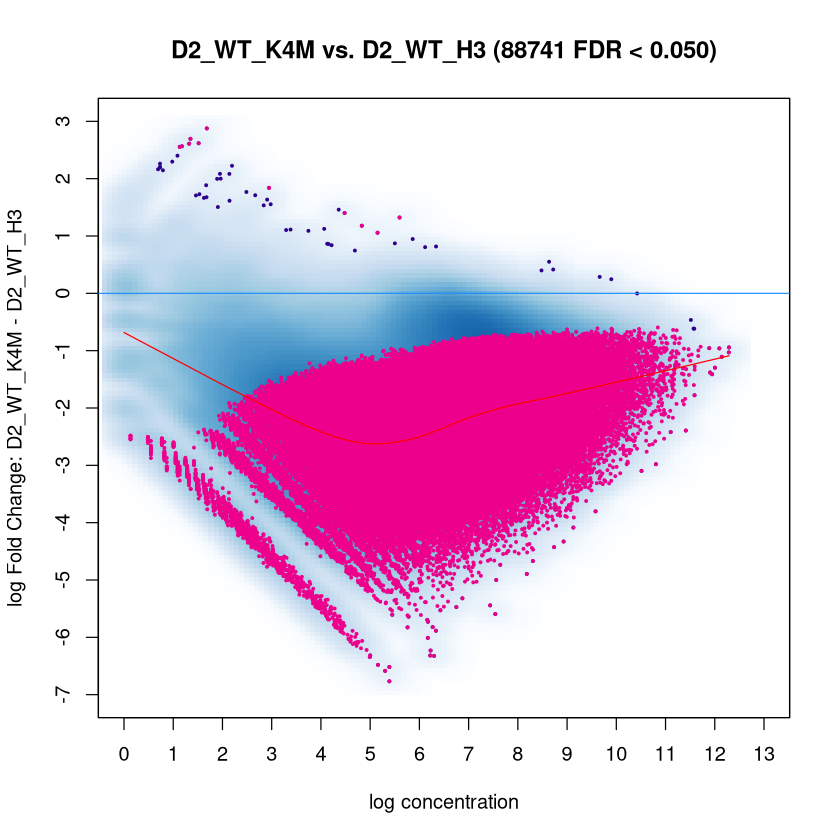

In [19]:
dba.plotMA(D2_db_H3_WT_vs_K4M_WT)

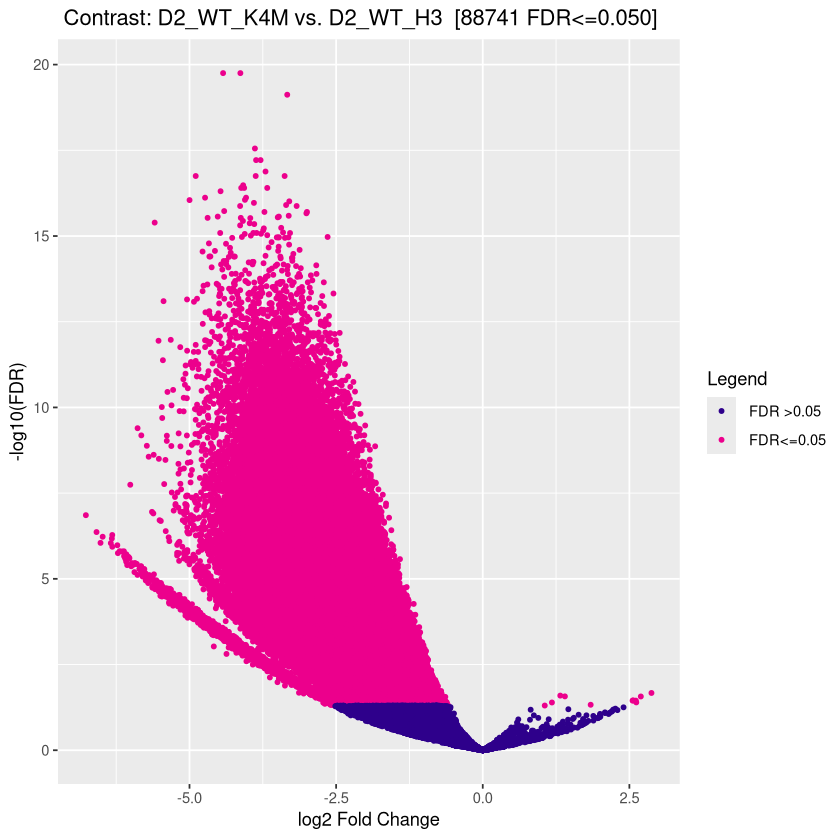

In [6]:
dba.plotVolcano(D2_db_H3_WT_vs_K4M_WT, contrast=1) 

In [21]:
pdf("Volcanoplot_diffbind_H3K4me1/D2_H3_WT_vs_K4M_WT.pdf", width = 8, height = 6)
dba.plotVolcano(D2_db_H3_WT_vs_K4M_WT, contrast=1) 
dev.off()

png 
  2

In [ ]:
setwd("/scratch/Narjesse/scripts/H3K4me1/Diffbind_Spikein/bed")
D2_WT_H3_enrich <- diff_peaks_D2_H3_WT_vs_K4M_WT %>% 
  dplyr::filter(FDR < 0.05 & Fold < 0) %>% 
  dplyr::select(seqnames, start, end,Fold)
# Write to file
write.table(D2_WT_H3_enrich, file="H3K4me1_D2_WT_H3_enriched_D0_H3_WT_vs_D2_K4M_WT.bed", sep="\t", quote=F, row.names=F, col.names=F)

D2_WT_K4M_enrich <- diff_peaks_D2_H3_WT_vs_K4M_WT %>% 
  dplyr::filter(FDR < 0.05 & Fold > 0) %>% 
  dplyr::select(seqnames, start, end)

# Write to file
write.table(D2_WT_K4M_enrich, file="D2_WT_K4M_enriched_D2_H3_WT_vs_D2_K4M_WT.bed", sep="\t", quote=F, row.names=F, col.names=F)

In [8]:
cat("number of D2 WT H3 enriched peaks :", nrow(D2_WT_H3_enrich),"\n")

number of D2 WT H3 enriched peaks : 88730 


In [9]:
cat("number of D2_WT_K4M_enrich peaks :", nrow(D2_WT_K4M_enrich))

number of D2_WT_K4M_enrich peaks : 11

# D0 TKO H3 vs D0 TKO K4M


In [22]:
D0_db_H3_TKO_vs_K4M_TKO <- dba.contrast(
  atac_db,
  contrast = c("Condition", "D0_TKO_K4M", "D0_TKO_H3"),
  minMembers = 2
)
D0_db_H3_TKO_vs_K4M_TKO <- dba.normalize(D0_db_H3_TKO_vs_K4M_TKO,spikein = TRUE)
D0_db_H3_TKO_vs_K4M_TKO <- dba.analyze(D0_db_H3_TKO_vs_K4M_TKO)
dba.show(D0_db_H3_TKO_vs_K4M_TKO, bContrasts = TRUE)

Computing results names...

Generating counts for spike-ins...

Applying Blacklist/Greylists...

Genome detected: Mmusculus.UCSC.mm10

Applying blacklist...

Removed: 1510 of 109563 intervals.

Re-normalizing...

Removed 1510 (of 109563) consensus peaks.

Analyzing...

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



,Factor,Group,Samples,Group2,Samples2,DB.DESeq2
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Condition,D0_TKO_K4M,2,D0_TKO_H3,2,65382


In [23]:
diff_peaks_D0_H3_TKO_vs_K4M_TKO <- dba.report(D0_db_H3_TKO_vs_K4M_TKO, th = 0.05)
length(diff_peaks_D0_H3_TKO_vs_K4M_TKO)
head(diff_peaks_D0_H3_TKO_vs_K4M_TKO)
diff_peaks_D0_H3_TKO_vs_K4M_TKO <- as.data.frame(diff_peaks_D0_H3_TKO_vs_K4M_TKO)

[1] 65382

GRanges object with 6 ranges and 6 metadata columns:
        seqnames              ranges strand |      Conc Conc_D0_TKO_K4M
           <Rle>           <IRanges>  <Rle> | <numeric>       <numeric>
  32461    chr14   66187227-66190851      * |   6.44416         2.16323
   1149     chr1   39291568-39295412      * |   8.01494         5.16160
   2831     chr1   84636598-84641411      * |   8.10206         5.13038
  94124     chr8     8607272-8610512      * |   7.98464         5.14915
  51164    chr19   17172717-17175624      * |   6.94359         3.53070
   7306     chr1 193544906-193545806      * |   6.66937         2.24673
        Conc_D0_TKO_H3      Fold     p-value         FDR
             <numeric> <numeric>   <numeric>   <numeric>
  32461        7.40657  -4.86540 8.31477e-22 8.81099e-17
   1149        8.91151  -3.63342 1.63086e-21 8.81099e-17
   2831        9.00704  -3.72128 6.11876e-21 1.67333e-16
  94124        8.87987  -3.62868 6.19449e-21 1.67333e-16
  51164        7.87422  -4.14

In [24]:
summary(diff_peaks_D0_H3_TKO_vs_K4M_TKO$Fold)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 -5.166  -2.594  -2.108  -2.147  -1.661   2.449 

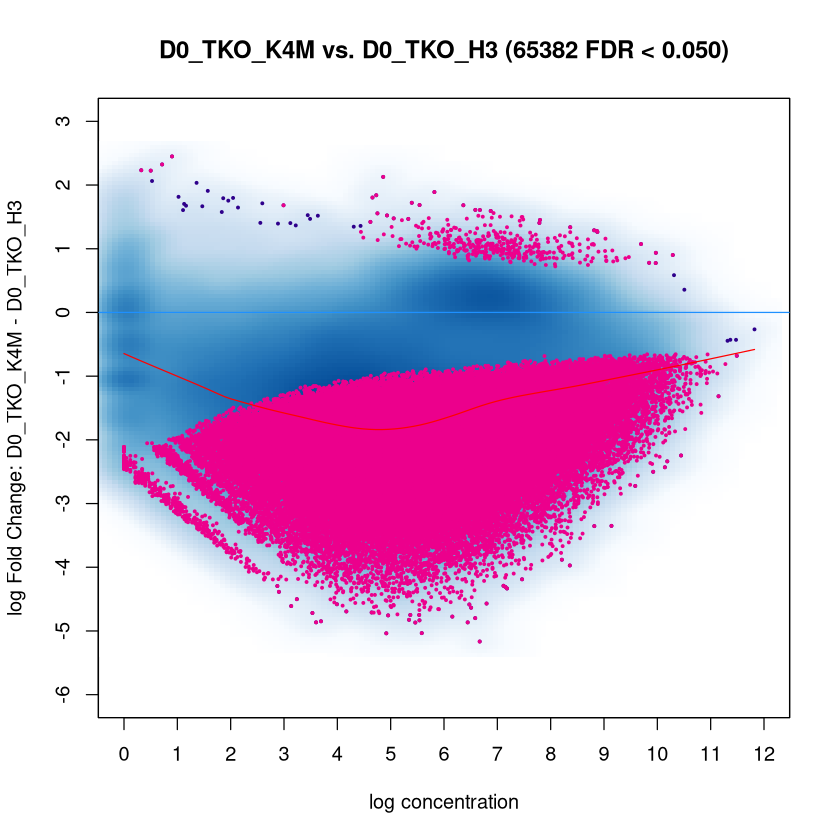

In [13]:
dba.plotMA(D0_db_H3_TKO_vs_K4M_TKO)

In [26]:
pdf("Volcanoplot_diffbind_H3K4me1/D0_H3_TKO_vs_K4M_TKO.pdf", width = 8, height = 6)
dba.plotVolcano(D0_db_H3_TKO_vs_K4M_TKO, contrast=1)
dev.off()

png 
  2

In [15]:
setwd("/scratch/Narjesse/scripts/H3K4me1/Diffbind_Spikein/bed")
D0_TKO_H3_enrich <- diff_peaks_D0_H3_TKO_vs_K4M_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold < 0) %>% 
  dplyr::select(seqnames, start, end)
# Write to file
write.table(D0_TKO_H3_enrich, file="D0_TKO_H3_enriched_D0_H3_TKO_vs_D0_K4M_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)

D0_TKO_K4M_enrich <- diff_peaks_D0_H3_TKO_vs_K4M_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold > 0) %>% 
  dplyr::select(seqnames, start, end)

# Write to file
write.table(D0_TKO_K4M_enrich, file="D0_TKO_K4M_enriched__D0_H3_TKO_vs_D0_K4M_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)

In [16]:
cat("number of D0_TKO_H3_enrich peaks :", nrow(D0_TKO_H3_enrich),"\n")

number of D0_TKO_H3_enrich peaks : 64992 


In [17]:
cat("number of D0_TKO_K4M_enrich peaks :", nrow(D0_TKO_K4M_enrich))

number of D0_TKO_K4M_enrich peaks : 390

### D2 TKO H3 VS D2 TKO K4M

In [27]:
D2_db_H3_TKO_vs_K4M_TKO <- dba.contrast(
  atac_db,
  contrast = c("Condition", "D2_TKO_K4M", "D2_TKO_H3"),
  minMembers = 2
)
D2_db_H3_TKO_vs_K4M_TKO <- dba.normalize(D2_db_H3_TKO_vs_K4M_TKO, spikein = TRUE)
D2_db_H3_TKO_vs_K4M_TKO <- dba.analyze(D2_db_H3_TKO_vs_K4M_TKO)
dba.show(D2_db_H3_TKO_vs_K4M_TKO, bContrasts = TRUE)

Computing results names...

Generating counts for spike-ins...

Applying Blacklist/Greylists...

Genome detected: Mmusculus.UCSC.mm10

Applying blacklist...

Removed: 1510 of 109563 intervals.

Re-normalizing...

Removed 1510 (of 109563) consensus peaks.

Analyzing...

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



,Factor,Group,Samples,Group2,Samples2,DB.DESeq2
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Condition,D2_TKO_K4M,2,D2_TKO_H3,2,102073


In [ ]:
df <- dba.report(D2_db_H3_TKO_vs_K4M_TKO,th = 1, DataType = DBA_DATA_FRAME)
write.table(df, file="Comparaison_diffbind_spikein_H3K4me1/D2_TKO_K4M_vs_D2_TKO_H3_H3K4me1.bed", sep="\t", quote=F, row.names=F, col.names=TRUE)


In [29]:
diff_peaks_D2_H3_TKO_vs_K4M_TKO <- dba.report(D2_db_H3_TKO_vs_K4M_TKO, th = 0.05)
length(diff_peaks_D2_H3_TKO_vs_K4M_TKO)
head(diff_peaks_D2_H3_TKO_vs_K4M_TKO)
diff_peaks_D2_H3_TKO_vs_K4M_TKO <- as.data.frame(diff_peaks_D2_H3_TKO_vs_K4M_TKO)

[1] 102073

GRanges object with 6 ranges and 6 metadata columns:
         seqnames              ranges strand |      Conc Conc_D2_TKO_K4M
            <Rle>           <IRanges>  <Rle> | <numeric>       <numeric>
   66662     chr3 138809027-138820348      * |  10.43641         6.15790
   53924     chr2   18977394-18980758      * |   8.86135         3.98934
    9176    chr10   45070630-45076751      * |   8.61222         4.78517
  102786     chr9   67537985-67542287      * |   9.02409         4.48881
    3792     chr1 118642428-118651467      * |   9.32954         6.00083
   43176    chr17   25753872-25757583      * |   9.33360         5.59818
         Conc_D2_TKO_H3      Fold     p-value         FDR
              <numeric> <numeric>   <numeric>   <numeric>
   66662       11.39875  -5.18804 5.48555e-47 5.92730e-42
   53924        9.83651  -5.76217 9.62066e-42 5.19771e-37
    9176        9.56048  -4.72680 1.00619e-40 3.62407e-36
  102786        9.99264  -5.43570 4.51901e-40 1.18579e-35
    3792       

In [13]:
df <- dba.report(D2_db_H3_TKO_vs_K4M_TKO,th = 1, DataType = DBA_DATA_FRAME)
write.table(df, file="/scratch/Narjesse/scripts/DNAme_over_ROI/H3K4me1_H3K4me3/H3K4me1_all_D2_H3_TKO_vs_D2_K4M_TKO.bed", sep="\t", quote=F, row.names=F, col.names=TRUE)


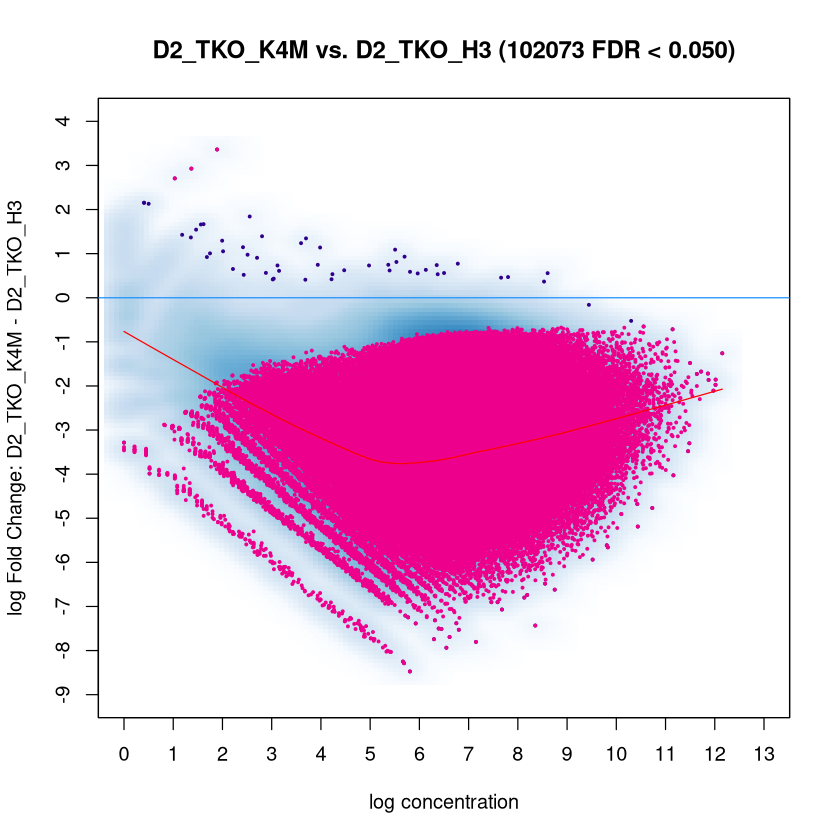

In [14]:
dba.plotMA(D2_db_H3_TKO_vs_K4M_TKO)

In [30]:
pdf("Volcanoplot_diffbind_H3K4me1/D2_H3_TKO_vs_K4M_TKO.pdf", width = 8, height = 6)
dba.plotVolcano(D2_db_H3_TKO_vs_K4M_TKO, contrast=1)
dev.off()

png 
  2

In [ ]:
setwd("/scratch/Narjesse/scripts/H3K4me1/Diffbind_Spikein/bed")
D2_TKO_H3_enrich <- diff_peaks_D2_H3_TKO_vs_K4M_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold < 0) %>% 
  dplyr::select(seqnames, start, end,Fold,FDR)
# Write to file
write.table(D2_TKO_H3_enrich, file="D2_TKO_H3_enriched_D2_H3_TKO_vs_D2_K4M_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)

D2_TKO_K4M_enrich <- diff_peaks_D2_H3_TKO_vs_K4M_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold > 0) %>% 
  dplyr::select(seqnames, start,end,Fold,FDR)

# Write to file
write.table(D2_TKO_K4M_enrich, file="D2_TKO_K4M_enriched__D2_H3_TKO_vs_D2_K4M_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)

In [9]:
cat("number of D2_TKO_H3_enrich peaks :", nrow(D2_TKO_H3_enrich),"\n")

number of D2_TKO_H3_enrich peaks : 102070 


In [10]:
cat("number of D2_TKO_K4M_enrich peaks :", nrow(D2_TKO_K4M_enrich))

number of D2_TKO_K4M_enrich peaks : 3

### D0 WT H3 vs  TKO H3 

In [4]:
D0_db_H3_WT_vs_H3_TKO <- dba.contrast(
  atac_db,
  contrast = c("Condition", "D0_TKO_H3", "D0_WT_H3"),
  minMembers = 2
)
D0_db_H3_WT_vs_H3_TKO <- dba.normalize(D0_db_H3_WT_vs_H3_TKO,spikein = TRUE )
D0_db_H3_WT_vs_H3_TKO <- dba.analyze(D0_db_H3_WT_vs_H3_TKO)
dba.show(D0_db_H3_WT_vs_H3_TKO, bContrasts = TRUE)

Computing results names...

Generating counts for spike-ins...

Applying Blacklist/Greylists...

Genome detected: Mmusculus.UCSC.mm10

Applying blacklist...

Removed: 1510 of 109563 intervals.

Re-normalizing...

Removed 1510 (of 109563) consensus peaks.

Analyzing...

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



,Factor,Group,Samples,Group2,Samples2,DB.DESeq2
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Condition,D0_TKO_H3,2,D0_WT_H3,2,217


In [5]:
diff_peaks_D0_H3_WT_vs_H3_TKO <- dba.report(D0_db_H3_WT_vs_H3_TKO, th = 0.05)
length(diff_peaks_D0_H3_WT_vs_H3_TKO)
head(diff_peaks_D0_H3_WT_vs_H3_TKO)
diff_peaks_D0_H3_WT_vs_H3_TKO <- as.data.frame(diff_peaks_D0_H3_WT_vs_H3_TKO)


[1] 217

GRanges object with 6 ranges and 6 metadata columns:
         seqnames              ranges strand |      Conc Conc_D0_TKO_H3
            <Rle>           <IRanges>  <Rle> | <numeric>      <numeric>
   12317    chr10 118665010-118668673      * |   6.61353        2.01036
   36161    chr15   72807992-72811025      * |   6.36542        7.30887
  107540     chrX 144459044-144462950      * |   7.60975        5.31207
   66944     chr3 148958324-148960887      * |   5.47843        2.63214
   64758     chr3   93407253-93410490      * |   5.89528        6.80475
   24185    chr12 107967483-107970145      * |   6.00513        3.85453
         Conc_D0_WT_H3      Fold     p-value         FDR
             <numeric> <numeric>   <numeric>   <numeric>
   12317       7.58354  -5.20477 4.44711e-14 4.33940e-09
   36161       2.66416   3.89227 6.79377e-13 3.31461e-08
  107540       8.45503  -2.47052 1.89599e-12 6.16689e-08
   66944       6.37447  -2.52115 1.61704e-09 3.94468e-05
   64758       2.85598   2.58

Warning message in KernSmooth::bkde2D(x, bandwidth = bandwidth, gridsize = nbin, :
“Binning grid too coarse for current (small) bandwidth: consider increasing 'gridsize'”


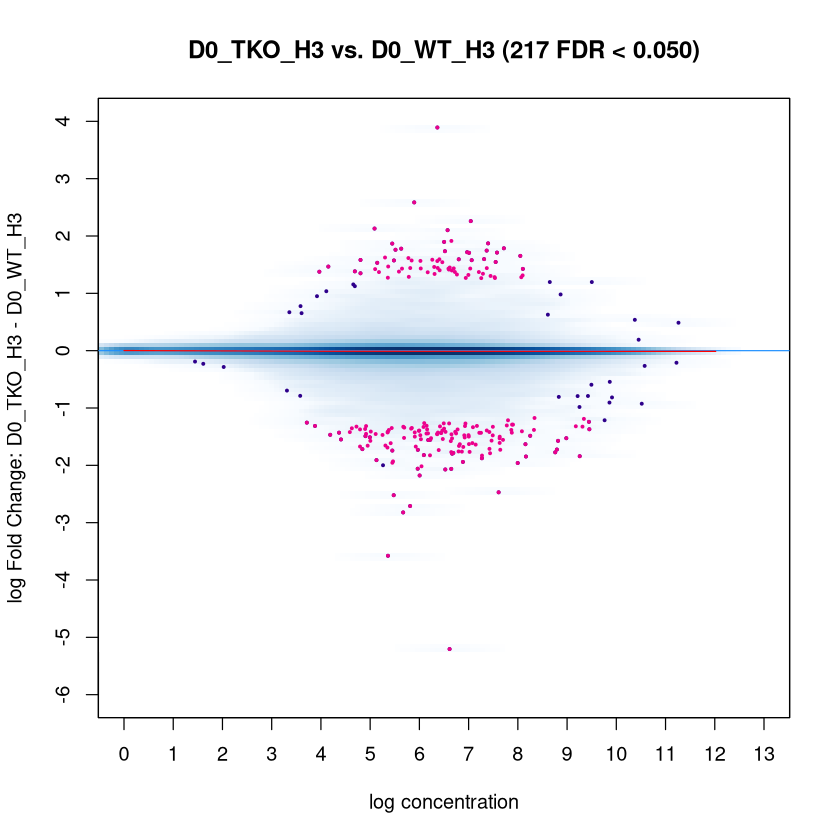

In [22]:
dba.plotMA(D0_db_H3_WT_vs_H3_TKO)

In [6]:
pdf("Volcanoplot_diffbind_H3K4me1/D0_H3_WT_vs_H3_TKO.pdf", width = 8, height = 6)
dba.plotVolcano(D0_db_H3_WT_vs_H3_TKO, contrast=1)
dev.off()

png 
  2

In [24]:
setwd("/scratch/Narjesse/scripts/H3K4me1/Diffbind_Spikein/bed")

D0_WT_H3_enrich <- diff_peaks_D0_H3_WT_vs_H3_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold < 0) %>% 
  dplyr::select(seqnames, start, end)
# Write to file
write.table(D0_WT_H3_enrich, file="D0_WT_H3_enriched_D0_H3_WT_vs_D0_H3_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)

D0_TKO_H3_enrich <- diff_peaks_D0_H3_WT_vs_H3_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold > 0) %>% 
  dplyr::select(seqnames, start, end)

# Write to file
write.table(D0_TKO_H3_enrich, file="D0_TKO_H3_enriched_D0_H3_WT_vs_D0_H3_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)

In [25]:
cat("number of D0_TKO_H3_enrich peaks :", nrow(D0_TKO_H3_enrich),"\n")

number of D0_TKO_H3_enrich peaks : 71 


In [26]:
cat("number of D0_WT_H3_enrich peaks :", nrow(D0_WT_H3_enrich))

number of D0_WT_H3_enrich peaks : 146

### D2 WT H3 vs  TKO H3 


In [7]:
D2_db_H3_WT_vs_H3_TKO <- dba.contrast(
  atac_db,
  contrast = c("Condition", "D2_TKO_H3", "D2_WT_H3"),
  minMembers = 2
)
D2_db_H3_WT_vs_H3_TKO <- dba.normalize(D2_db_H3_WT_vs_H3_TKO, spikein = TRUE)
D2_db_H3_WT_vs_H3_TKO <- dba.analyze(D2_db_H3_WT_vs_H3_TKO)
dba.show(D2_db_H3_WT_vs_H3_TKO, bContrasts = TRUE)

Computing results names...

Generating counts for spike-ins...

Applying Blacklist/Greylists...

Genome detected: Mmusculus.UCSC.mm10

Applying blacklist...

Removed: 1510 of 109563 intervals.

Re-normalizing...

Removed 1510 (of 109563) consensus peaks.

Analyzing...

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



,Factor,Group,Samples,Group2,Samples2,DB.DESeq2
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Condition,D2_TKO_H3,2,D2_WT_H3,2,6030


In [8]:
df <- dba.report(D2_db_H3_WT_vs_H3_TKO,th = 1, DataType = DBA_DATA_FRAME)
write.table(df, file="Comparaison_diffbind_spikein_H3K4me1/D2_WT_H3_vs_D2_TKO_H3_H3K4me1.bed", sep="\t", quote=F, row.names=F, col.names=TRUE)


Warning message in file(file, ifelse(append, "a", "w")):
“cannot open file 'Comparaison_diffbind_spikein_H3K4me1/D2_WT_H3_vs_D2_TKO_H3_H3K4me1.bed': No such file or directory”


ERROR: Error in file(file, ifelse(append, "a", "w")): cannot open the connection


In [10]:
diff_peaks_D2_H3_WT_vs_H3_TKO <- dba.report(D2_db_H3_WT_vs_H3_TKO, th = 0.05)
length(diff_peaks_D2_H3_WT_vs_H3_TKO)
head(diff_peaks_D2_H3_WT_vs_H3_TKO)
diff_peaks_D2_H3_WT_vs_H3_TKO <- as.data.frame(diff_peaks_D2_H3_WT_vs_H3_TKO)

[1] 6030

GRanges object with 6 ranges and 6 metadata columns:
        seqnames              ranges strand |      Conc Conc_D2_TKO_H3
           <Rle>           <IRanges>  <Rle> | <numeric>      <numeric>
  79784     chr5 129657465-129661995      * |   7.70424        8.61700
  36161    chr15   72807992-72811025      * |   7.24706        8.20362
  75754     chr5   36876280-36878511      * |   7.60810        8.50549
  60360     chr2 157807156-157810491      * |   8.63341        9.46317
  30030    chr14   12082265-12084785      * |   7.74675        8.62300
  55885     chr2   59382946-59387762      * |   8.59579        9.32733
        Conc_D2_WT_H3      Fold     p-value         FDR
            <numeric> <numeric>   <numeric>   <numeric>
  79784       4.61320   2.91582 1.13860e-13 6.61817e-09
  36161       3.17157   3.33745 1.22499e-13 6.61817e-09
  75754       4.74353   2.57928 4.57905e-11 1.64927e-06
  60360       6.46601   2.20118 8.68634e-10 2.34646e-05
  30030       5.14203   2.36817 1.25879e-09

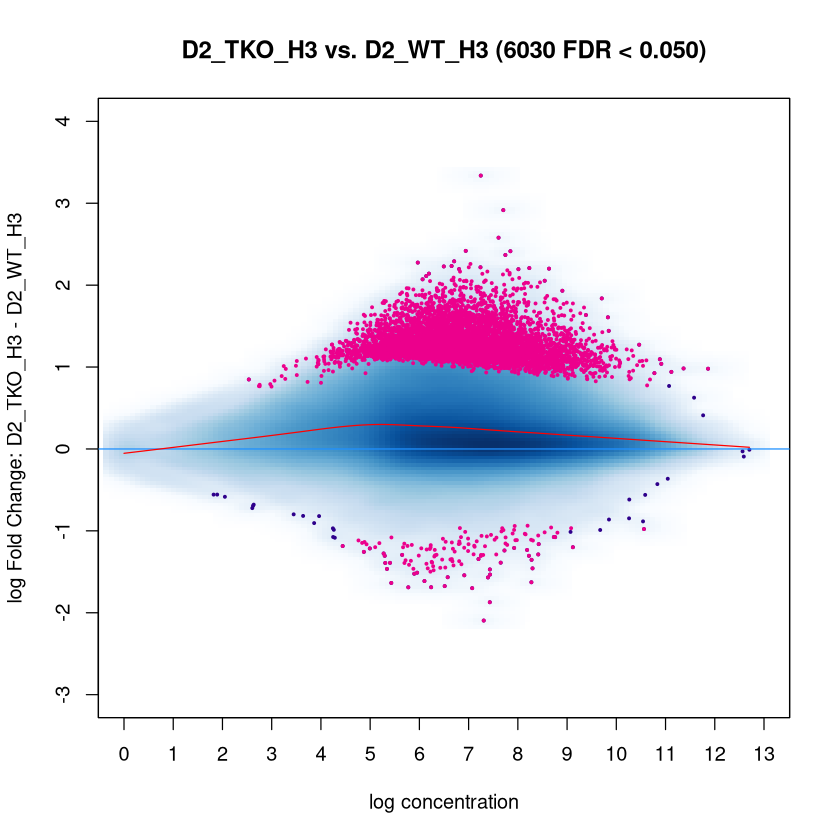

In [5]:
dba.plotMA(D2_db_H3_WT_vs_H3_TKO)


In [11]:
pdf("Volcanoplot_diffbind_H3K4me1/D2_H3_WT_vs_H3_TKO.pdf", width = 8, height = 6)
dba.plotVolcano(D2_db_H3_WT_vs_H3_TKO, contrast=1)
dev.off()


png 
  2

In [ ]:
setwd("/scratch/Narjesse/scripts/H3K4me1/Diffbind_Spikein/bed")

D2_WT_H3_enrich <- diff_peaks_D2_H3_WT_vs_H3_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold < 0) %>% 
  dplyr::select(seqnames, start, end)
# Write to file
write.table(D2_WT_H3_enrich, file="D2_WT_H3_enriched_D2_H3_WT_vs_D2_H3_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)

D2_TKO_H3_enrich <- diff_peaks_D2_H3_WT_vs_H3_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold > 0) %>% 
  dplyr::select(seqnames, start, end)

# Write to file
write.table(D2_TKO_H3_enrich, file="D2_TKO_H3_enriched_D2_H3_WT_vs_D2_H3_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)

In [8]:
cat("number of D2_TKO_H3_enrich peaks :", nrow(D2_TKO_H3_enrich),"\n")

number of D2_TKO_H3_enrich peaks : 5898 


In [9]:
cat("number of D2_WT_H3_enrich peaks :", nrow(D2_WT_H3_enrich))


number of D2_WT_H3_enrich peaks : 132

### D0 WT K4M vs  TKO K4M


In [3]:
D0_db_K4M_WT_vs_K4M_TKO <- dba.contrast(
  atac_db,
  contrast = c("Condition", "D0_TKO_K4M", "D0_WT_K4M"),
  minMembers = 2
)
D0_db_K4M_WT_vs_K4M_TKO <- dba.normalize(D0_db_K4M_WT_vs_K4M_TKO,spikein = TRUE)
D0_db_K4M_WT_vs_K4M_TKO <- dba.analyze(D0_db_K4M_WT_vs_K4M_TKO)
dba.show(D0_db_K4M_WT_vs_K4M_TKO, bContrasts = TRUE)

Computing results names...

Generating counts for spike-ins...

Applying Blacklist/Greylists...

Genome detected: Mmusculus.UCSC.mm10

Applying blacklist...

Removed: 1510 of 109563 intervals.

Re-normalizing...

Removed 1510 (of 109563) consensus peaks.

Analyzing...

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



,Factor,Group,Samples,Group2,Samples2,DB.DESeq2
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Condition,D0_TKO_K4M,2,D0_WT_K4M,2,947


In [4]:
diff_peaks_K4M_WT_vs_K4M_TKO <- dba.report(D0_db_K4M_WT_vs_K4M_TKO, th = 0.05)
length(diff_peaks_K4M_WT_vs_K4M_TKO)
head(diff_peaks_K4M_WT_vs_K4M_TKO)
diff_peaks_K4M_WT_vs_K4M_TKO <- as.data.frame(diff_peaks_K4M_WT_vs_K4M_TKO)

[1] 947

GRanges object with 6 ranges and 6 metadata columns:
         seqnames              ranges strand |      Conc Conc_D0_TKO_K4M
            <Rle>           <IRanges>  <Rle> | <numeric>       <numeric>
   36161    chr15   72807992-72811025      * |   6.22239         7.15393
  107540     chrX 144459044-144462950      * |   5.40368         2.08635
   98114     chr8 106515199-106520925      * |   8.54383         9.34683
   48230    chr18   38905709-38908425      * |   7.22407         5.23443
   27473    chr13   60608189-60613613      * |   7.18717         5.06059
   56030     chr2   60808077-60812186      * |   6.69175         4.59092
         Conc_D0_WT_K4M      Fold     p-value         FDR
              <numeric> <numeric>   <numeric>   <numeric>
   36161        2.79095   3.05189 6.77953e-15 4.80946e-10
  107540        6.32944  -3.04177 1.16011e-14 4.80946e-10
   98114        6.57396   2.24652 1.91001e-12 5.27888e-08
   48230        8.02994  -2.26568 3.84197e-12 7.96382e-08
   27473       

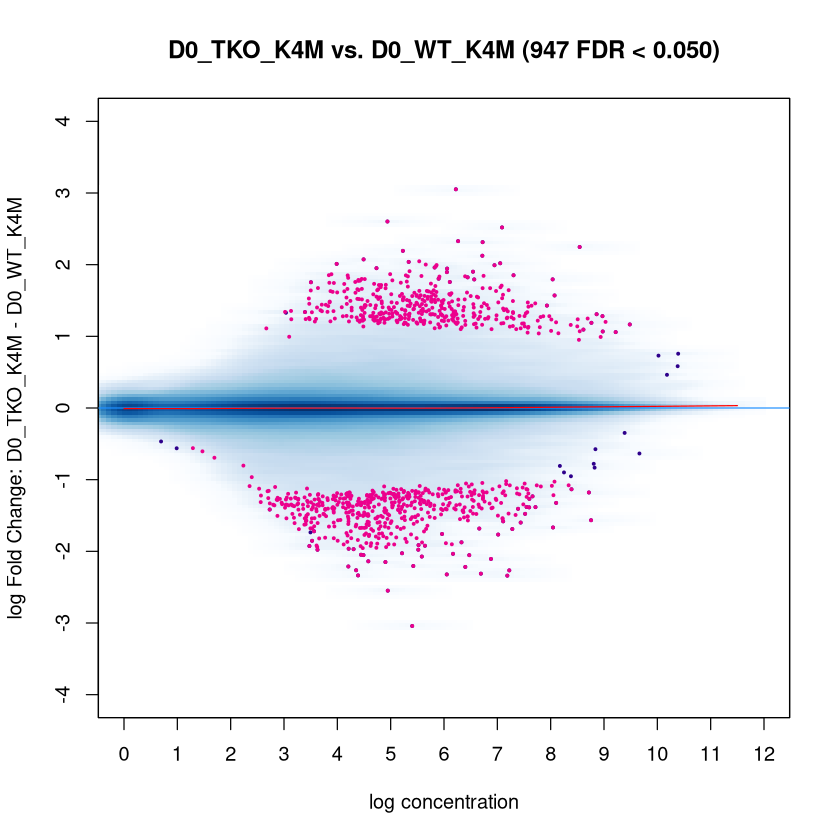

In [5]:
dba.plotMA(D0_db_K4M_WT_vs_K4M_TKO)

In [6]:
pdf("Volcanoplot_diffbind_H3K4me1/D0_K4M_WT_vs_K4M_TKO.pdf", width = 8, height = 6)
dba.plotVolcano(D0_db_K4M_WT_vs_K4M_TKO, contrast=1)
dev.off()


png 
  2

In [14]:
setwd("/scratch/Narjesse/scripts/H3K4me1/Diffbind_Spikein/bed")

D0_WT_K4M_enrich <- diff_peaks_K4M_WT_vs_K4M_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold < 0) %>% 
  dplyr::select(seqnames, start, end)
# Write to file
write.table(D0_WT_K4M_enrich, file="D0_WT_K4M_enriched_D0_K4M_WT_vs_D0_K4M_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)

D0_TKO_K4M_enrich <- diff_peaks_K4M_WT_vs_K4M_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold > 0) %>% 
  dplyr::select(seqnames, start, end)

# Write to file
write.table(D0_TKO_K4M_enrich, file="D0_TKO_K4M_enriched_D0_K4M_WT_vs_D0_K4M_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)

In [15]:
cat("number of D0_WT_K4M_enrich peaks :", nrow(D0_WT_K4M_enrich),"\n")

number of D0_WT_K4M_enrich peaks : 531 


In [16]:
cat("number of D0_TKO_K4M_enrich peaks :", nrow(D0_TKO_K4M_enrich),"\n")

number of D0_TKO_K4M_enrich peaks : 416 


### D2 WT K4M vs  TKO K4M


In [4]:
D2_db_K4M_WT_vs_K4M_TKO <- dba.contrast(
  atac_db,
  contrast = c("Condition", "D2_TKO_K4M", "D2_WT_K4M"),
  minMembers = 2
)
D2_db_K4M_WT_vs_K4M_TKO <- dba.normalize(D2_db_K4M_WT_vs_K4M_TKO,spikein = TRUE)
D2_db_K4M_WT_vs_K4M_TKO <- dba.analyze(D2_db_K4M_WT_vs_K4M_TKO)
dba.show(D2_db_K4M_WT_vs_K4M_TKO, bContrasts = TRUE)

Computing results names...

Generating counts for spike-ins...

Applying Blacklist/Greylists...

Genome detected: Mmusculus.UCSC.mm10

Applying blacklist...

Removed: 1510 of 109563 intervals.

Re-normalizing...

Removed 1510 (of 109563) consensus peaks.

Analyzing...

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



,Factor,Group,Samples,Group2,Samples2,DB.DESeq2
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Condition,D2_TKO_K4M,2,D2_WT_K4M,2,11405


In [5]:
df <- dba.report(D2_db_K4M_WT_vs_K4M_TKO,th = 1, DataType = DBA_DATA_FRAME)
write.table(df, file="Comparaison_diffbind_spikein_H3K4me1/D2_WT_K4M_vs_D2_TKO_K4M_H3K4me1.bed", sep="\t", quote=F, row.names=F, col.names=TRUE)


Warning message in file(file, ifelse(append, "a", "w")):
“cannot open file 'Comparaison_diffbind_spikein_H3K4me1/D2_WT_K4M_vs_D2_TKO_K4M_H3K4me1.bed': No such file or directory”


ERROR: Error in file(file, ifelse(append, "a", "w")): cannot open the connection


In [6]:
diff_peaks_D2_K4M_WT_vs_K4M_TKO <- dba.report(D2_db_K4M_WT_vs_K4M_TKO, th = 0.05)
length(diff_peaks_D2_K4M_WT_vs_K4M_TKO)
head(diff_peaks_D2_K4M_WT_vs_K4M_TKO)
diff_peaks_D2_K4M_WT_vs_K4M_TKO <- as.data.frame(diff_peaks_D2_K4M_WT_vs_K4M_TKO)

[1] 11405

GRanges object with 6 ranges and 6 metadata columns:
        seqnames              ranges strand |      Conc Conc_D2_TKO_K4M
           <Rle>           <IRanges>  <Rle> | <numeric>       <numeric>
  58067     chr2 116018942-116022665      * |   6.35988         3.67839
  90566     chr7   79137755-79141279      * |   5.86389         3.86721
  10240    chr10   75001341-75004295      * |   6.16342         3.32345
  11792    chr10 107488420-107489563      * |   5.29092         2.09265
  44919    chr17   48998092-49000822      * |   5.46752         2.53902
  16086    chr11   68393350-68395736      * |   5.79934         2.88527
        Conc_D2_WT_K4M      Fold     p-value         FDR
             <numeric> <numeric>   <numeric>   <numeric>
  58067        7.24281  -2.82638 3.79829e-13 2.70102e-08
  90566        6.67077  -2.40231 5.30819e-13 2.70102e-08
  10240        7.05899  -2.88205 1.05168e-12 3.56758e-08
  11792        6.21010  -2.98777 2.87216e-12 5.97778e-08
  44919        6.36952  -2.89

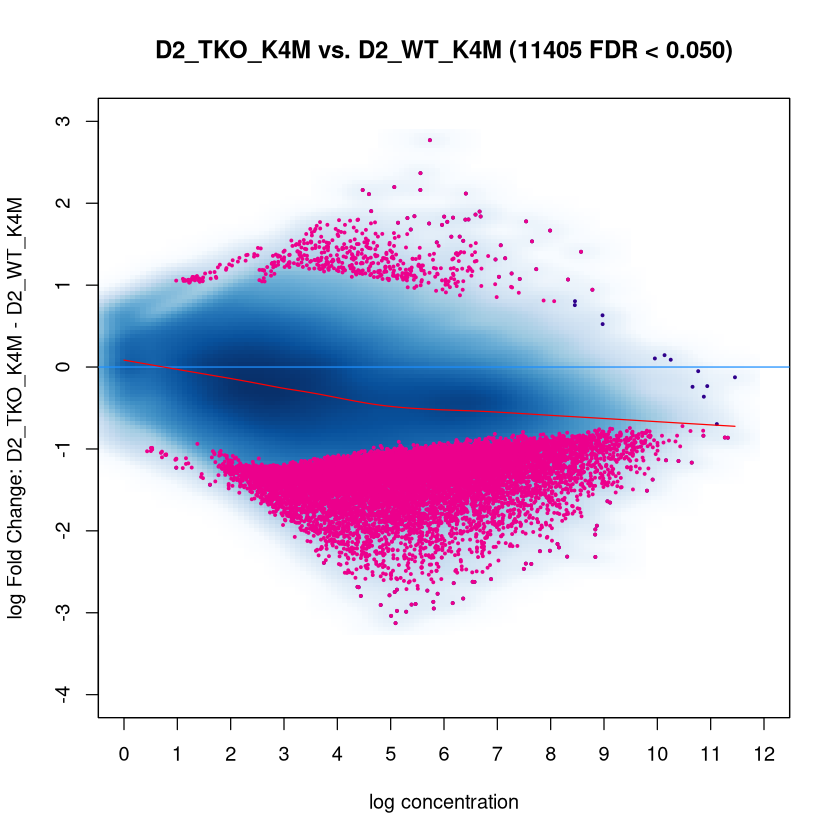

In [19]:
dba.plotMA(D2_db_K4M_WT_vs_K4M_TKO)

In [8]:
pdf("Volcanoplot_diffbind_H3K4me1/D2_K4M_WT_vs_K4M_TKO.pdf", width = 8, height = 6)
dba.plotVolcano(D2_db_K4M_WT_vs_K4M_TKO, contrast=1)
dev.off()


png 
  2

In [21]:
setwd("/scratch/Narjesse/scripts/H3K4me1/Diffbind_Spikein/bed")
library(dplyr)
D2_WT_K4M_enrich <- diff_peaks_D2_K4M_WT_vs_K4M_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold < 0) %>% 
  dplyr::select(seqnames, start, end)
# Write to file
write.table(D2_WT_K4M_enrich, file="D2_WT_K4M_enriched_D2_K4M_WT_vs_D2_K4M_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)
D2_TKO_K4M_enrich <- diff_peaks_D2_K4M_WT_vs_K4M_TKO %>% 
  dplyr::filter(FDR < 0.05 & Fold > 0) %>% 
  dplyr::select(seqnames, start, end)

# Write to file
write.table(D2_TKO_K4M_enrich, file="D2_TKO_K4M_enriched_D2_K4M_WT_vs_D2_K4M_TKO.bed", sep="\t", quote=F, row.names=F, col.names=F)

In [22]:
cat("number of D2_WT_K4M_enrich peaks :", nrow(D2_WT_K4M_enrich),"\n")

number of D2_WT_K4M_enrich peaks : 10895 


In [23]:
cat("number of D2_TKO_K4M_enrich peaks :", nrow(D2_TKO_K4M_enrich))

number of D2_TKO_K4M_enrich peaks : 510